In [1]:
# Setup: install the checker and download the public tests (run this cell first)
%pip install -q otter-grader==7.0.0

import os, urllib.request
TESTS_URL = "https://raw.githubusercontent.com/NaiveNeuron/ml_exercises/master/assignment1/tests/"
os.makedirs("tests", exist_ok=True)
for q in ["q1_reshape", "q2_mean", "q4_zero_every_second", "q5_set_lower", "q6_average", "q7_linear_loops", "q8_linear_vectorized", "q9_sliding_window"]:
    path = os.path.join("tests", q + ".py")
    if not os.path.exists(path):
        urllib.request.urlretrieve(TESTS_URL + q + ".py", path)

import otter
grader = otter.Notebook()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 145.5/145.5 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 101.6/101.6 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.2/119.2 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.1/88.1 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 38.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 39.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.2/48.2 MB 18.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 623.8/623.8 kB 18.5 MB/s eta 0:00:00


 ## Introduction to numpy

As the title says, welcome to this introductory notebook where we will try to learn something about `numpy`.

Throughout this notebook you will be asked to solve exercises. Each of them is marked with a heading such as

<h5 style="color: #1B1BFF">Exercise 1</h5>

and followed by a `grader.check(...)` cell (for instance, `grader.check("q1_reshape")` checks Exercise 1).

------------------------------

Writing clean vectorized `numpy` code is in many cases essential. Familiarity with this tool will help you write code that is both elegant and efficient and thus leads into faster and more effective experiemnts. Much more importantly, however, it will become easier for you to rewrite matematical equations because your code **will read like equations**. So lets start with some basics.

### Grading

This tutorial is worth up to **10 points** towards your semester grade (see the [course info](https://compbio.fmph.uniba.sk/vyuka/ml/info.php)). You get the points only if you complete **all exercises** in this notebook (Exercises 1 to 9), including the final question at the end (Exercise 9). Solving only the final question earns no points.

After each exercise you will find a `grader.check(...)` cell. Run it to check your answer against basic tests. Passing these checks does not guarantee the points: when grading, we run additional tests.

In [2]:
import numpy as np

First, the imports. While it is not strictly required, most of the time you will find `numpy` to be imported as `np`. We suggest you do the same in your own projects/scripts.

If you would want to create a vector `a` in `numpy` you can do so as follows:

In [3]:
a = np.array([2, 4, 5, 6])
print(a)

[2 4 5 6]


To create a matrix you can use same syntax as you would for 2D arrays in Python

In [4]:
A = np.array([[1, 2, 3, 4],
              [5, 6, 7, 8]])
print(A)

[[1 2 3 4]
 [5 6 7 8]]


Through this tutorial, we will try to keep the names of vectors (which will be lower-case) and matricies (which will
be keep upper-case) constant.

Since we now know how to create basic numpy objects, lets talk about them a bit.

All objects like these (vector, matrix...) have a **shape** attribute which describes, as the name suggests, their shape. In other words, it descibes what do the dimensions of a particular object look like. This attribute can be accesed by typing `.shape` after the name of the object.

Here are some examples:

In [5]:
# create a vector
a = np.array([1, 2, 3, 4])
print("{}\n".format(a))

# create a 2D matrix
A = np.array([[1, 2, 3, 4],
              [1, 2, 3, 4]])
print("{}\n".format(A))

# create 3D matrix (literally a 3D Python array wrapped in np.array)
B = np.array([[[1, 2], [1, 2],
               [3, 4], [3, 4]],
              [[4, 5], [5, 6],
               [4, 5], [5, 6]]])
print("{}\n".format(B))

# print shapes of all create objects
print("Shape of vector a is {}".format(a.shape))
print("Shape of matrix A is {}".format(A.shape))
print("Shape of matrix B is {}".format(B.shape))

[1 2 3 4]

[[1 2 3 4]
 [1 2 3 4]]

[[[1 2]
  [1 2]
  [3 4]
  [3 4]]

 [[4 5]
  [5 6]
  [4 5]
  [5 6]]]

Shape of vector a is (4,)
Shape of matrix A is (2, 4)
Shape of matrix B is (2, 4, 2)


Throughout this course we will mostly work with high dimensional objects.

In scientific computation practice, it is often needed to create a multidimensional object with certain values, such as an array with all elements equal to zero or a matrix initialized with values sampled from the normal distribution.

Luckilly, `numpy` is awesome in this regard, as it provides readily-available solutions to pretty much all of the "standard needs". If you feel like "someone must have done this before", chances are there is a `numpy` function for it.

Here are some examples of usage of functions for matrix and array creation that you may find useful:

In [6]:
# creates a vector with elements [0, 1, 2, 3, 4]
a = np.arange(5)
print("a = {}".format(a))

# we can also set its starting point. So to create vector [10, 11, 12, 13, 14]
# we would do
v = np.arange(10, 15)
print("v = {}".format(v))

# and also we can set step size. So to create a vector with elements spaced by 10
# with start at 10 and end at 40, that is [10, 20, 30, 40] we would do
u = np.arange(10, 50, 10)
print("u = {}".format(u))

# Create a matrix filled with zeros of shape (10, 5)
A = np.zeros((10, 5))
print("A =")
print(A)

# Create a matrix filled with ones of shape (5, 10)
B = np.ones((5, 10))
print("B =")
print(B)

a = [0 1 2 3 4]
v = [10 11 12 13 14]
u = [10 20 30 40]
A =
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]
B =
[[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]]


In [7]:
# Create a 2D matrix with random values of shape (5, 5)
X = np.random.rand(5, 5)
print("X with shape {}".format(X.shape))
print(X)

# Create 3D matrix with values sampled from normal distribution of shape (2, 3, 2)
Y = np.random.randn(2, 3, 2)
print("\nY with shape {}".format(Y.shape))
print(Y)

X with shape (5, 5)
[[0.6556398  0.04514905 0.82362851 0.50707739 0.03891386]
 [0.4643263  0.06119984 0.87219897 0.45054038 0.53399762]
 [0.75431236 0.60820006 0.73415667 0.78468869 0.75173988]
 [0.4373263  0.52500827 0.07197518 0.29053036 0.54250455]
 [0.05822938 0.28022291 0.11981175 0.45091718 0.39079965]]

Y with shape (2, 3, 2)
[[[ 0.03504976 -2.78169317]
  [-0.44054931 -0.84411598]
  [-1.90546797 -1.78026435]]

 [[ 1.30949541 -1.52461233]
  [ 0.24329596 -0.83043116]
  [ 1.814338    0.04891724]]]


Once we have these objects initalized, there are a ton of aritmetic operations we can do with them:

In [8]:
a = np.array([1, 2, 3, 4, 5])
print("a = {}".format(a))

# add a constant value to each element of a vector
print("a + 5 = {}".format(a + 5))

# multiply each element of a vector by a constant value
print("a * 5 = {}".format(a * 5))

# square the vector a
print("a^2 = {}".format(a ** 2))

v = np.array([2, 2, 3, 2, 3])
print("v = {}".format(v))

# multiply vector a by  vector v
print("a * v = {}".format(a * v))

a = [1 2 3 4 5]
a + 5 = [ 6  7  8  9 10]
a * 5 = [ 5 10 15 20 25]
a^2 = [ 1  4  9 16 25]
v = [2 2 3 2 3]
a * v = [ 2  4  9  8 15]


To multiply matrices together (to get their **element-wise** or [Hadamard](https://en.wikipedia.org/wiki/Hadamard_product_(matrices)) product, not the **dot product**), we do not need to do anything special:

In [9]:
A = np.array([[1, 2, 3],
              [1, 2, 3]])
B = np.array([[2, 2, 2],
              [3, 3, 3]])
print("A =\n{}".format(A))
print("B =\n{}".format(B))
print("")
print("A * B =\n{}".format(A * B))

A =
[[1 2 3]
 [1 2 3]]
B =
[[2 2 2]
 [3 3 3]]

A * B =
[[2 4 6]
 [3 6 9]]



We can also do other standard matrix operations with `numpy`, such as **dot product**.

In [10]:
A = np.random.rand(2, 3)
print("A with shape {}\n".format(A.shape))
print(A)
B = np.random.randn(3, 5)
print("B with shape {}\n".format(B.shape))
print(B)
print("\nA \dot B =")
# dot product of 'A' and 'B' to create a tensor of size (2, 5)
print(A.dot(B))

A with shape (2, 3)

[[0.49888165 0.85069683 0.87326946]
 [0.54773138 0.52505728 0.76208311]]
B with shape (3, 5)

[[-0.5056521   0.21638614 -0.46786564 -1.20565343  0.32865445]
 [-1.16334122 -0.49742425  0.34055388  2.3979322   0.75078757]
 [ 0.61423827  1.62358784  0.04346771  0.96749595 -0.34589159]]

A \dot B =
[[-0.70551572  1.10262352  0.09425755  2.28331962  0.50059571]
 [-0.41968169  1.09465413 -0.04432839  1.33598987  0.31062269]]


<>:7: SyntaxWarning: invalid escape sequence '\d'
<>:7: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_1061/1997926889.py:7: SyntaxWarning: invalid escape sequence '\d'
  print("\nA \dot B =")


Oftentimes your vectors/matricies will have a shape that is just not what you would want.

For instance, your data can be (and often times will be) stored in a common data storing formats like CSV. These formats are easily loadable with Python but not very usefull, since our models will almost certainly require vectors or matricies of certain shape. To reshape our vectors/matricies, numpy provides a `.reshape` function.

For example, suppose we would find interesting data that consits of 100 gray scale images each having `36 x 36`px and loaded it into our Python environment. Note that since these are grayscale images, each pixel is represented as a single scalar value.

Long story short, our matrix would have shape `(100, 36, 36)`. Now, we would like to use this to train some model. But our model takes a vector, not a matrix. We can easily preprocess this data accordingly with `numpy`.

In [11]:
# loaded matrix
X = np.random.randn(100, 36, 36)

# print shape of matrix X
print("Shape of a matrix X is {}\n".format(X.shape))

# reshape matrix X to contain 100 vectors
Y = np.reshape(X, (100, 36 * 36))

# print shape of new matrix Y
print("Shape of new reshaped matrix Y is {}".format(Y.shape))

Shape of a matrix X is (100, 36, 36)

Shape of new reshaped matrix Y is (100, 1296)


-------------------------------

<h5 style="color: #1B1BFF">Exercise 1</h5>

Reshape vector X, such that after the reshape operation it will contain 100 examples -- each of those with dimensions 240, 240, 3. Store the reshaped array in `X_reshaped`.

In [12]:
X = np.random.randn(17280000)

# RESHAPE HERE
X_reshaped = np.reshape(X, (100, 240, 240, 3))

print("New reshape vector X with shape: {}".format(X_reshaped.shape))

New reshape vector X with shape: (100, 240, 240, 3)


In [13]:
grader.check("q1_reshape")

q1_reshape results: All test cases passed!

------------------------------------------

You may also often times need to find the `sum` or `mean` of a vector or a matrix.

For all operations like this `numpy` already provides an implemented function (`mean`, `sum`, ...). These functions can also take an optional `axis` argument, which specifies in which axis should an operation be executed.

For instance, if we would like to take a sum of the first axis of vector `x` we would do something like `np.sum(x, axis=0)` (dimension are indexed from zero).

In [14]:
# create some matrix x
X = np.array([[1, 3, 5, 7],
              [6, 7, 3, 1],
              [1, 4, 5, 1],
              [7, 8, 4, 3],
              [1, 2, 3, 4],
              [9, 5, 4, 3],
              [9, 8, 7, 6]])
print("Shape of X: {}\n".format(X.shape))

# take sum of first axis
s = np.sum(X, axis=0)
print("sum of first dimension of matrix x: \ns={}\n".format(s))

print("Shape of s: {}".format(s.shape))

Shape of X: (7, 4)

sum of first dimension of matrix x: 
s=[34 37 31 25]

Shape of s: (4,)


-------------------------------

<h5 style="color: #1B1BFF">Exercise 2</h5>

Find the mean of the matrix `Z` in the second dimension and store it in `Z_mean`. Furthermore, store the dimensions of this resulting matrix in `Z_mean_shape` (we print them for you).

In [19]:
Z = np.random.rand(10, 10, 15)

## Mean of the Z matrix in the second dimension:
Z_mean = np.mean(Z, axis=1)

## Dimensions of the result
Z_mean_shape = Z_mean.shape
print(Z_mean_shape)

(10, 15)


In [20]:
grader.check("q2_mean")

q2_mean results: All test cases passed!

<!-- BEGIN QUESTION -->

<h5 style="color: #1B1BFF">Exercise 3</h5>

How would dimensions change if we would have taken the mean of the last (third) axis? Please also *briefly* explain what would the output of the `mean` operation represent if we changed the `axis` parameter.

Write your answer into the `q3_answer` string in the cell below.

In [ ]:
# Write your answer as plain text between the triple quotes.
q3_answer = """
Dimensions of the result would be (10, 10). The output of such mean operation
would be a 2D (10, 10) matrix where each element with position (x, y) is a mean
of all elements of the last dimension at the position (x, y) in the previous
matrix
"""

<!-- END QUESTION -->

---------------------------------------

`numpy` also supports an operation called **broadcasting**. This can be better explained on some example.
Let us assume we have a 2D matrix with 10 training examples, each of them having 3 features (matrix `X` of shape (10, 3)). Further suppose we also have a vector `w` of weights for each feature of size `(3, )`.

Now, we would like to weigh each one of our traning examples with our wieght vector `w`. In plain Python we would probably have to write 2 `for` loops. With `numpy` it seems that since we can multiply vectors, we could probably make do with just one.

Thankfully, all of this has been taken care of for us by **broadcasting**. In the end, all we need is a simple multiplication:

In [22]:
# create random weight vector w
w = np.random.randn(3)
print("w with shape {}".format(w.shape))
print(w)

# create random matrix X
X = (np.random.rand(10, 3) * 10) + 3
print("X with shape {}".format(X.shape))
print(X)
print("")

# multiply each vector of shape (3,) in a second
# dimension of matrix X by weight vector w
print("Multiplication result:")
print(X * w)

w with shape (3,)
[ 0.0152713   0.08296335 -0.74830439]
X with shape (10, 3)
[[ 6.97521357 10.85333234  7.80396292]
 [11.28709391  8.60316844 12.849964  ]
 [ 5.41382101  9.12612962  4.57633086]
 [10.74456925 11.53159418  5.95387868]
 [ 5.31550808 10.36502488 11.72099232]
 [ 7.61576957 10.16675622  5.535659  ]
 [ 7.16001269  7.8362414   8.43000063]
 [ 9.26458603 11.63653749  9.54288847]
 [12.10011423  7.10050394  5.11323622]
 [ 7.35598855  5.47685473 12.77886155]]

Multiplication result:
[[ 0.10652057  0.90042884 -5.83973972]
 [ 0.17236859  0.7137477  -9.61568448]
 [ 0.08267608  0.75713431 -3.42448848]
 [ 0.16408353  0.95669972 -4.45531356]
 [ 0.08117471  0.85991722 -8.77087001]
 [ 0.1163027   0.84346819 -4.14235793]
 [ 0.1093427   0.65012086 -6.30820648]
 [ 0.14148226  0.96540617 -7.14098534]
 [ 0.18478446  0.58908161 -3.82625711]
 [ 0.1123355   0.45437823 -9.5624782 ]]


If we would want to set all elements in the second dimension of the first element of some matrix to zero, we can also do so with `numpy`s broadcasting by simply typing **:** instead of a number in a specific dimension.

*Note*: the magical colon **:** here is actually the delimeter -- part of the syntax for "slicing" Python sequences (of any kind, really). For instance,

- `[1:5]` is equivalent to saying "from 1 to 5"
- `[:5]` is equivalent to saying "from beginning to 5"
- `[1:]` is equivalent to saying "from 1 to end"

Taking all of this into consideration, in the end we get `[:]` which can be equivalently described as "from beginning to end"

In [23]:
# create random matrix X
X = np.random.randn(4, 3)
print("X =\n{}".format(X))
print("")

# set all elements of a first dimension to zero
X[0, :] = 0

print("X =\n{}".format(X))

X =
[[ 0.25900551 -1.04602722 -0.6981595 ]
 [ 2.49627554 -0.06834344  0.69464689]
 [-0.33239713  0.03678623  0.80536986]
 [ 0.70453554  1.94644442 -0.62651362]]

X =
[[ 0.          0.          0.        ]
 [ 2.49627554 -0.06834344  0.69464689]
 [-0.33239713  0.03678623  0.80536986]
 [ 0.70453554  1.94644442 -0.62651362]]


`numpy` also supports indexing by specifying a vector of indexes and then passing it to a "sliceable" object (i.e. matrix or vector). Or you can also specify a boolean matrix/vector (in other words a *mask*) and pass it to any object of this sort. Values in places with `True` value will be picked up while values on `False` places will be ignored.

In [24]:
# create matrix X filled with ones
X = np.ones((4, 3))
print("X =\n{}\n".format(X))

# create vector of indecies for matrix X
idx = [0, 3]
X[idx] = 0
print("After running X[idx] = 0")
print("X =\n{}\n".format(X))

# create boolean matrix to select only certain values
bool_idx = np.zeros((4, 3)).astype('bool')
bool_idx[2, 2] = True
bool_idx[3, 2] = True
bool_idx[1, 0] = True
print("bool_idx =\n{}\n".format(bool_idx))

# set each values specified in bool_idx to 300
X[bool_idx] = 300
print("After running X[bool_idx] = 300")
print("X =\n{}".format(X))

X =
[[1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]]

After running X[idx] = 0
X =
[[0. 0. 0.]
 [1. 1. 1.]
 [1. 1. 1.]
 [0. 0. 0.]]

bool_idx =
[[False False False]
 [ True False False]
 [False False  True]
 [False False  True]]

After running X[bool_idx] = 300
X =
[[  0.   0.   0.]
 [300.   1.   1.]
 [  1.   1. 300.]
 [  0.   0. 300.]]


These operations are usually heavily optimized in the background, so in most cases it is worth writing **vectorized** code with `numpy` rather than loops (even if it may take some time to figure out how to actually do that).

We can also compare values in numpy arrays. Comparing an array or a matrix with some value will return an array or a matrix of the same shape but with boolean values. If the value in a certain position meets the specified condition, the resulting matrix will have `True` value in that position. If it does not meet the condition, it will be `False`.

In [25]:
# create matrix X
X = np.array([[1, 4, 3, 5],
              [1, 2, 3, 7],
              [5, 6, 2, 7]])
print("X =\n{}\n".format(X))

# get all values that are more than 3
print("X > 3 =\n{}".format(X > 3))

X =
[[1 4 3 5]
 [1 2 3 7]
 [5 6 2 7]]

X > 3 =
[[False  True False  True]
 [False False False  True]
 [ True  True False  True]]


As we can see, this nicely combines with what we learned before on `numpy`'s support for indexing by a boolean array/matrix. So if we want to set all the values that are bigger than `3` to say `300`, we can just do:

In [26]:
print("X =\n{}\n".format(X))

# get all values that are more than 3
bool_idx = X > 3
print("X > 3 =\n{}".format(bool_idx))

# set all those values to 300
X[bool_idx] = 300
print("X =\n{}\n".format(X))

X =
[[1 4 3 5]
 [1 2 3 7]
 [5 6 2 7]]

X > 3 =
[[False  True False  True]
 [False False False  True]
 [ True  True False  True]]
X =
[[  1 300   3 300]
 [  1   2   3 300]
 [300 300   2 300]]



-------------------------------

<h5 style="color: #1B1BFF">Exercise 4</h5>

Create random array of shape (10, 10, 3) that will have every second element (starting with index 1) in the second dimension set to zero. Store it in `R`.

In [27]:
R = np.random.rand(10,10,3)
R[:, 1::2, :] = 0
print("R =\n{}".format(R))

R =
[[[0.76159731 0.07839361 0.87043862]
  [0.         0.         0.        ]
  [0.84813986 0.48384894 0.37427726]
  [0.         0.         0.        ]
  [0.05214405 0.75191671 0.44095991]
  [0.         0.         0.        ]
  [0.76311419 0.8547965  0.30987111]
  [0.         0.         0.        ]
  [0.76801628 0.44210984 0.7049907 ]
  [0.         0.         0.        ]]

 [[0.16115482 0.55009091 0.8124501 ]
  [0.         0.         0.        ]
  [0.85700092 0.07129705 0.87105401]
  [0.         0.         0.        ]
  [0.29925317 0.91109915 0.39665172]
  [0.         0.         0.        ]
  [0.13983642 0.76128393 0.62929287]
  [0.         0.         0.        ]
  [0.3710426  0.26150468 0.43639032]
  [0.         0.         0.        ]]

 [[0.67284907 0.40817379 0.81476789]
  [0.         0.         0.        ]
  [0.61559274 0.63167557 0.99567734]
  [0.         0.         0.        ]
  [0.05054004 0.21220913 0.82182948]
  [0.         0.         0.        ]
  [0.32101088 0.95601596 0.183

In [28]:
grader.check("q4_zero_every_second")

q4_zero_every_second results: All test cases passed!

<h5 style="color: #1B1BFF">Exercise 5</h5>

Create a function that will set all the elements of a given array/matrix under a specified threshold to a specific value (we prepared the function header for you). The function should modify the given array in place.

In [33]:
def set_lower(X, thresh, value):
    X[X<thresh] = value


X = np.array([[1, 3, 5],
              [3, 5, 1],
              [1, 2, 5]])
set_lower(X, 3, 5000)
print("X =\n{}".format(X))

Y = np.random.randn(100, 100, 100)
set_lower(Y, 0.5, 1)

X =
[[5000    3    5]
 [   3    5 5000]
 [5000 5000    5]]


In [34]:
grader.check("q5_set_lower")

q5_set_lower results: All test cases passed!

------------------------------------------

**And much more...** if you are iterested, all operations can be found in the [**offical documentation**](https://docs.scipy.org/doc/numpy/contents.html).

Furthermore, if you would like to familiarize yourself with `numpy` even more, we suggest you take a look at the [**Numpy Excercises**](https://github.com/Kyubyong/numpy_exercises).


Now for the fun part of this excercise.


We'll import some helper functions first and get right back to the excercises.

In [35]:
import time
import functools
from matplotlib import pyplot as plt


def timeit(func):
    """
    Profiling function to measure time it takes to finish function.

    Args:
        func(*function): Function to meassure

    Returns:
        (*function) New wrapped function with meassurment
    """
    @functools.wraps(func)
    def newfunc(*args, **kwargs):
        start_time = time.time()
        out = func(*args, **kwargs)
        elapsed_time = time.time() - start_time
        ftime = elapsed_time
        msg = "function [{}] finished in {} ms"
        print(msg.format(func.__name__, ftime))
        return out
    return newfunc


def show_cut_image(x):
    f, axarr = plt.subplots(4, 4)
    rnd = x[np.random.randint(x.shape[0], size=16)]
    for i in range(4):
        for j in range(4):
            axarr[i, j].imshow(rnd[i + j * 4])
            axarr[i, j].axis('off')
    plt.show()


------------------

<h5 style="color: #1B1BFF">Exercise 6</h5>

Rewrite this matematical equation first with the use of loops and then as functional vectorized numpy code:

$$y = \frac{1}{n}\sum_i^n{X_i}$$

In [36]:
X = np.arange(50)

def operate_loops_avg(X):
    y = 0
    for i in X:
      y += i
    return y / len(X)

operate_loops_avg(X)

np.float64(24.5)

In [37]:
X = np.arange(50)

def operate_vectorized_avg(X):
    y = np.mean(X)
    return y

operate_vectorized_avg(X)

np.float64(24.5)

In [38]:
grader.check("q6_average")

q6_average results: All test cases passed!

<h5 style="color: #1B1BFF">Exercise 7</h5>

Rewrite this matematical equation with the use of `for` loops. Please use the prepared function header.

$$y = \sum_j \sum_n \big(\sum_m X_{j,m} \cdot W_{m,n}\big) + b_{n}$$

where $b$ is a vector, $X_j$ is an input vector for the example $j$ and $W$ is a weight matrix.

In [39]:
A = np.random.rand(10, 100)
B = np.random.rand(100, 100)
c = np.random.rand(100)

@timeit
def operate_loops(X, W, b):
    y = 0
    for j in range(X.shape[0]):
        for n in range(W.shape[1]):
            for m in range(W.shape[0]):
                y += X[j, m] * W[m, n]
            y += b[n]
    return y

for x in range(10):
    operate_loops(A, B, c)

function [operate_loops] finished in 0.04637956619262695 ms
function [operate_loops] finished in 0.06182694435119629 ms
function [operate_loops] finished in 0.04243898391723633 ms
function [operate_loops] finished in 0.041643381118774414 ms
function [operate_loops] finished in 0.043042659759521484 ms
function [operate_loops] finished in 0.049230098724365234 ms
function [operate_loops] finished in 0.04491591453552246 ms
function [operate_loops] finished in 0.042176008224487305 ms
function [operate_loops] finished in 0.0414280891418457 ms
function [operate_loops] finished in 0.044208526611328125 ms


In [40]:
grader.check("q7_linear_loops")

function [operate_loops] finished in 7.772445678710938e-05 ms


q7_linear_loops results: All test cases passed!

<h5 style="color: #1B1BFF">Exercise 8</h5>

Now write the same equation but as numpy vectorized code. Difference between results of these two functions should be **zero** or **very close to zero**.

In [41]:
@timeit
def operate_vectorized(X, W, b):
    y = np.sum(X.dot(W) + b)
    return y

for x in range(10):
    operate_vectorized(A, B, c)

# print("Difference: {}".format(np.sum(np.abs(operate_vectorized(A, B, c) - operate_loops(A, B, c)))))

function [operate_vectorized] finished in 0.0008280277252197266 ms
function [operate_vectorized] finished in 0.0006368160247802734 ms
function [operate_vectorized] finished in 7.557868957519531e-05 ms
function [operate_vectorized] finished in 4.9114227294921875e-05 ms
function [operate_vectorized] finished in 4.3392181396484375e-05 ms
function [operate_vectorized] finished in 4.76837158203125e-05 ms
function [operate_vectorized] finished in 4.482269287109375e-05 ms
function [operate_vectorized] finished in 4.458427429199219e-05 ms
function [operate_vectorized] finished in 4.506111145019531e-05 ms
function [operate_vectorized] finished in 4.649162292480469e-05 ms


In [42]:
grader.check("q8_linear_vectorized")

function [operate_vectorized] finished in 8.344650268554688e-05 ms


q8_linear_vectorized results: All test cases passed!

As you can see, the `numpy` vectorized code runs much faster. This is due to the fact that vectorized operations, broadcasting and native `numpy` functions are heavily optimized to run as eficiently as possible.

------------------------------------------------------------------------------------------------------------------

### Final question (Exercise 9):

We loaded a picture for you in the cell below. With just reshape and function `moveaxis()` (check out the offical docs) split the image into equal chunks. In other words, simulate sliding window cutter that will cutout window of size `80 x 80` each **80 pixels**. Your final array should have shape `108 x 80 x 80 x 3`. This should not take more than few lines of code. You can also pass the final array to `show_cut_image(<your array here>)` function to see some of your cutouts. Store the result in `cuts`.

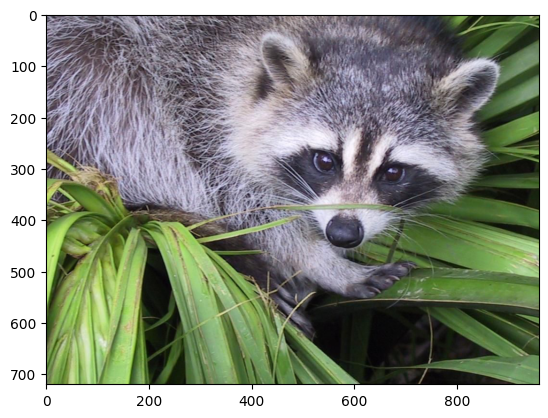

Image shape: (720, 960, 3)


In [51]:
from scipy import datasets
import skimage.transform
import matplotlib.pyplot as plt

img = datasets.face()
img = skimage.transform.resize(img, (720, 960))
plt.imshow(img)
plt.show()

print("Image shape: {}".format(img.shape))

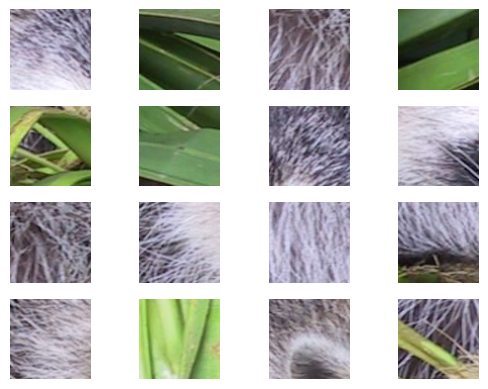

In [78]:
# RESHAPE AND ROLL HERE
cuts = img.reshape(9, 80, 12, 80, 3)
cuts = np.moveaxis(cuts, 2, 1)
cuts = cuts.reshape(108, 80, 80, 3)

show_cut_image(cuts)

In [79]:
grader.check("q9_sliding_window")

q9_sliding_window results: All test cases passed!

### Submission details


*Remember: the points require completing the whole notebook, including the final question (see **Grading** at the top of this notebook).*

*If you need any help with this assignment, please feel free to ask the course TAs during their office hours, which can be found at the [course website](http://compbio.fmph.uniba.sk/vyuka/ml/).*


## This is all for now. Thank you!